In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score, log_loss, classification_report
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import export_graphviz
import graphviz
import pydotplus
from IPython.display import Image

In [2]:
file_path = input("Please enter the file path: ")
df = pd.read_csv(file_path, delimiter=',', encoding='latin1')
df = df.copy()


## Data exploration

In [3]:
df.head(20)

,leeft,alg_v1b,zorg_v6,stijl_v1a,stijl_v3a,stijl_v5,act_v11a,act_v11b,act_v11c,act_v11d,nogmdiag,fam_v1,tumsoort,tijddiagn,ther_chemo,ther_rt,ther_ht
0,35.0,1.0,1.0,2.0,2.0,0.0,0.000000,1.399198,6.979753,0.000000,1.0,1.0,803330.0,15.304699,0.0,1.0,0.0
1,39.0,1.0,0.0,2.0,NaN,0.0,4.153060,0.720159,7.607269,13.513303,1.0,1.0,801310.0,8.071463,0.0,1.0,0.0
2,34.0,0.0,1.0,2.0,3.0,0.0,0.640075,15.918381,2.253323,NaN,1.0,1.0,102310.0,5.309839,0.0,0.0,0.0
3,35.0,0.0,0.0,2.0,3.0,0.0,NaN,NaN,NaN,NaN,1.0,3.0,453330.0,17.940959,0.0,0.0,0.0
4,22.0,0.0,1.0,1.0,3.0,1.0,6.060652,2.868083,4.600431,3.873778,1.0,1.0,104310.0,12.316856,1.0,0.0,0.0
5,35.0,0.0,0.0,2.0,3.0,1.0,12.594034,0.000000,8.385894,0.000000,3.0,2.0,901310.0,12.983757,0.0,0.0,0.0
6,21.0,0.0,0.0,1.0,3.0,1.0,3.584276,24.014187,2.598993,NaN,1.0,1.0,441310.0,10.750937,0.0,0.0,0.0
7,29.0,1.0,1.0,1.0,3.0,0.0,12.224000,5.200335,5.864884,0.000000,1.0,1.0,801310.0,9.430637,1.0,1.0,0.0
8,28.0,1.0,0.0,1.0,3.0,0.0,4.653725,26.033483,6.618855,10.940727,2.0,1.0,501300.0,14.307061,1.0,1.0,0.0
9,35.0,0.0,0.0,1.0,3.0,0.0,3.162270,1.485217,4.751455,8.736725,1.0,1.0,441310.0,9.675084,1.0,0.0,0.0


## Prep/remap - Covars

In [4]:
df.drop(columns=['act_v11b', 'act_v11d', 'tumsoort'], inplace=True) # dropped mins in wk and wknd, and tumor type

# Rename columns
df.rename(columns={
    'nogmdiag': 'cancer_rec',
    'leeft': 'age',
    'alg_v1b': 'sex',
    'zorg_v6': 'follow_up_status',
    'stijl_v1a': 'smoking',
    'stijl_v3a': 'alcohol',
    'stijl_v5': 'drug_use',
    'fam_v1':'family_history',
    'ther_chemo': 'chemotherapy',
    'ther_rt': 'radiation',
    'ther_ht': 'hormone_therapy',
    'tijddiagn': 'time_diag',
}, inplace=True)

# dichotmize covars
df['smoking'] = df['smoking'].replace({1: 0, 2: 0, 3: 1})
df['alcohol'] = df['alcohol'].replace({1: 0, 2: 0, 3: 1})
df['follow_up_status'] = df['follow_up_status'].replace({2: 0})
df['family_history'] = df['family_history'].replace({1: 0, 2: 1, 3: 1, 4: 2}) # 2 because they kept 'idk'.

# Sedentary behavior
# summed act_v11a and act_v11c into their own named column, 'sed_beh' then dropped them  #took out minutes in wk and wknd
df['sed_beh'] = df['act_v11a'] + df['act_v11c']
df['sed_beh'] = df['sed_beh'].round(2)
df = df.drop(columns=['act_v11a', 'act_v11c'])

#dichtoimize y
df['cancer_rec'] = df['cancer_rec'].replace({1:0, 2:0, 3:1}) # 3: Yes, a different kind of cancer, namely
df = df[df.cancer_rec != 4] #drop idk in cancer_rec

# drop rows with missing values
df.dropna(inplace=True)

# assign X and y
y = df['cancer_rec']
X = df.drop(columns=['cancer_rec'])


In [5]:
print(df.info()) #check renamed

<class 'pandas.core.frame.DataFrame'>
Index: 946 entries, 0 to 1099
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               946 non-null    float64
 1   sex               946 non-null    float64
 2   follow_up_status  946 non-null    float64
 3   smoking           946 non-null    float64
 4   alcohol           946 non-null    float64
 5   drug_use          946 non-null    float64
 6   cancer_rec        946 non-null    float64
 7   family_history    946 non-null    float64
 8   time_diag         946 non-null    float64
 9   chemotherapy      946 non-null    float64
 10  radiation         946 non-null    float64
 11  hormone_therapy   946 non-null    float64
 12  sed_beh           946 non-null    float64
dtypes: float64(13)
memory usage: 103.5 KB
None


## Median (IQR)
Unsure how they worked with sed_beh. See table 1

In [6]:
# median (IQR) of sedentary behaviour for total pop
# Calculate the median
median_value_X = X['sed_beh'].median()
print(f'Median: {median_value_X:.2f}')

# Calculate the 25th percentile (Q1)
q1 = X['sed_beh'].quantile(0.25)
print(f'25th percentile (Q1): {q1:.2f}')

# Calculate the 75th percentile (Q3)
q3 = X['sed_beh'].quantile(0.75)
print(f'75th percentile (Q3): {q3:.2f}')

# Calculate the IQR
iqr = q3 - q1
print(f'IQR: {iqr:.2f}')

Median: 14.11
25th percentile (Q1): 10.00
75th percentile (Q3): 18.47
IQR: 8.47


In [7]:
# 1 if sed_beh is over median (for now) ####
X['sed_beh'] = X['sed_beh'].apply(lambda x: 1 if x >= 14.29 else 0).astype('float64') 

In [8]:
print (X.head(20))

     age  sex  follow_up_status  smoking  alcohol  drug_use  family_history  \
0   35.0  1.0               1.0      0.0      0.0       0.0             0.0   
2   34.0  0.0               1.0      0.0      1.0       0.0             0.0   
4   22.0  0.0               1.0      0.0      1.0       1.0             0.0   
5   35.0  0.0               0.0      0.0      1.0       1.0             1.0   
6   21.0  0.0               0.0      0.0      1.0       1.0             0.0   
7   29.0  1.0               1.0      0.0      1.0       0.0             0.0   
8   28.0  1.0               0.0      0.0      1.0       0.0             0.0   
9   35.0  0.0               0.0      0.0      1.0       0.0             0.0   
10  22.0  0.0               0.0      0.0      1.0       0.0             0.0   
12  19.0  0.0               1.0      0.0      1.0       1.0             0.0   
13  32.0  0.0               1.0      0.0      1.0       0.0             0.0   
14  32.0  1.0               0.0      0.0      1.0   

In [9]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 946 entries, 0 to 1099
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               946 non-null    float64
 1   sex               946 non-null    float64
 2   follow_up_status  946 non-null    float64
 3   smoking           946 non-null    float64
 4   alcohol           946 non-null    float64
 5   drug_use          946 non-null    float64
 6   family_history    946 non-null    float64
 7   time_diag         946 non-null    float64
 8   chemotherapy      946 non-null    float64
 9   radiation         946 non-null    float64
 10  hormone_therapy   946 non-null    float64
 11  sed_beh           946 non-null    float64
dtypes: float64(12)
memory usage: 96.1 KB


array([[<Axes: title={'center': 'age'}>, <Axes: title={'center': 'sex'}>,
        <Axes: title={'center': 'follow_up_status'}>],
       [<Axes: title={'center': 'smoking'}>,
        <Axes: title={'center': 'alcohol'}>,
        <Axes: title={'center': 'drug_use'}>],
       [<Axes: title={'center': 'family_history'}>,
        <Axes: title={'center': 'time_diag'}>,
        <Axes: title={'center': 'chemotherapy'}>],
       [<Axes: title={'center': 'radiation'}>,
        <Axes: title={'center': 'hormone_therapy'}>,
        <Axes: title={'center': 'sed_beh'}>]], dtype=object)

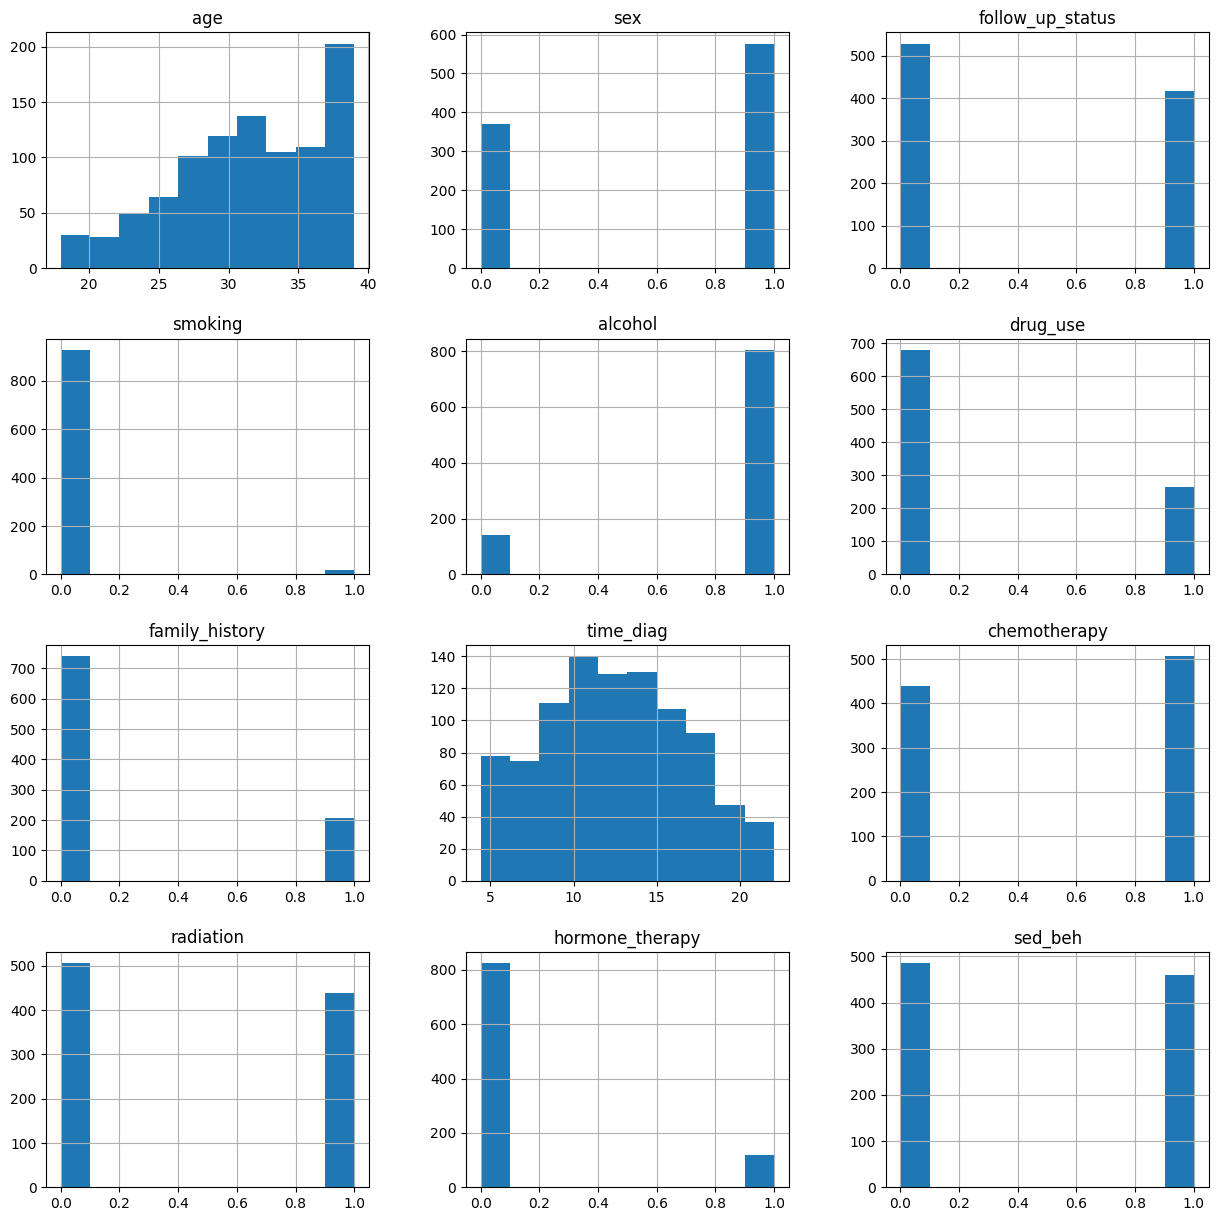

In [10]:
X.hist(figsize=(15, 15))

## Introduce train/test & Scale the data

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize/scale the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(y_test.shape)
print(y_train.shape)
print(X_test.shape)
print(X_train.shape)

(190,)
(756,)
(190, 12)
(756, 12)


## Check correlation with cancer recurrence

In [12]:
df.corr()['cancer_rec'].sort_values(ascending=False)

cancer_rec          1.000000
drug_use            0.063840
age                 0.037343
family_history      0.029721
hormone_therapy     0.023903
chemotherapy        0.023698
sed_beh             0.014951
sex                -0.012756
alcohol            -0.013732
smoking            -0.018268
follow_up_status   -0.033896
time_diag          -0.038367
radiation          -0.056300
Name: cancer_rec, dtype: float64

## Log Regression - Plain

In [13]:
log_reg = LogisticRegression(class_weight='balanced')
log_reg.fit(X_train, y_train)

LogisticRegression(class_weight='balanced')

In [14]:
# Make predictions using the testing set
y_pred = log_reg.predict(X_test) #predicted labels for X test set. Returns class w highest prob for each sample. Binary outcome
y_prob = log_reg.predict_proba(X_test)[:, 1]

In [24]:
y_test.value_counts()

cancer_rec
0.0    187
1.0      3
Name: count, dtype: int64

## Evaluations - Plain

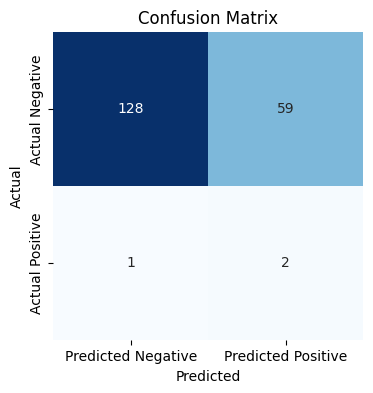

/var/folders/6z/8jmv33nx765dnhhppmf26ljc0000gp/T/ipykernel_5497/1633477322.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best')


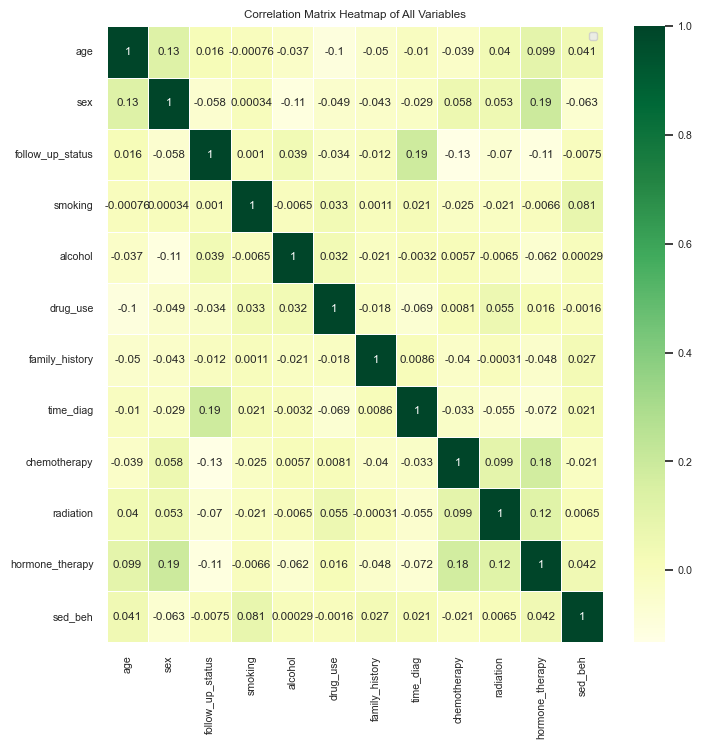

Classification Report:
              precision    recall  f1-score   support

         0.0       0.99      0.68      0.81       187
         1.0       0.03      0.67      0.06         3

    accuracy                           0.68       190
   macro avg       0.51      0.68      0.44       190
weighted avg       0.98      0.68      0.80       190



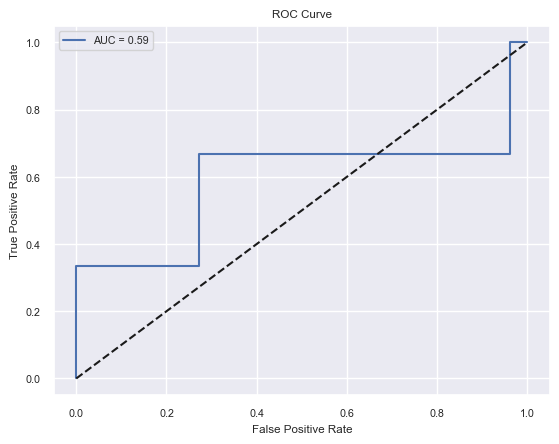

AUC: 0.5882352941176471
Class distribution in y_pred: {np.float64(0.0): np.int64(187), np.float64(1.0): np.int64(3)}
             Feature  Coefficient  Odds Ratio
5           drug_use     0.631772    1.880940
8       chemotherapy     0.352626    1.422799
0                age     0.321659    1.379414
11           sed_beh     0.192314    1.212052
6     family_history     0.160591    1.174205
1                sex     0.119076    1.126456
10   hormone_therapy     0.113406    1.120086
7          time_diag     0.030871    1.031352
4            alcohol     0.013239    1.013327
2   follow_up_status    -0.116718    0.889836
9          radiation    -0.633385    0.530792
3            smoking    -0.659509    0.517105


In [15]:
#Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Correlation matrix
correlation_matrix = X.corr()
plt.figure(figsize=(8, 8))
sns.set(font_scale=0.7)
sns.heatmap(correlation_matrix, annot=True, cmap="YlGn", linewidths=.5)
plt.title("Correlation Matrix Heatmap of All Variables")
plt.legend(loc='best')
plt.show()

print('Classification Report:')
print(classification_report(y_test, y_pred))

# The coefficients
coef = log_reg.coef_

# Convert coefficients to odds ratios
odds_ratios = np.exp(coef)

# ROC Curve and AUC
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob, average='micro') # micro: Calculate metrics globally by counting the total true positives, false negatives and false positives.    

plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='best')
plt.show()
print('AUC:', auc)

unique_test, counts_test = np.unique(y_test, return_counts=True)
print(f'Class distribution in y_pred: {dict(zip(unique_test, counts_test))}')

# Flatten the arrays to ensure they are 1-dimensional
coef_odds = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coef.flatten(),
    'Odds Ratio': odds_ratios.flatten()
})

coef_odds_sorted = coef_odds.sort_values(by='Coefficient', ascending=False)
print(coef_odds_sorted)



## Log Regression - Elastic Net
Grid Search

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train) # calculate weights of each class in a balanced manner
class_weight_dict = {i: class_weights[i] for i in range(len(class_weights))}

# Define the parameter grid for the log reg
param_grid = {
    'l1_ratio': [0.1, 0.5, 0.7, 0.9, 1.0],  # Range of l1_ratio values to search
    'C': [0.1, 1, 10, 100]  # Range of regularization strengths
    # right now c = 10 & l1 ratio is 0.9 but is thgat still good enough?
}

# Initialize the logistic regression model with class weights
elastic_model = LogisticRegression(penalty='elasticnet', solver ='saga', max_iter=1000, class_weight=class_weight_dict)

# Initialize GridSearchCV
grid_search = GridSearchCV(elastic_model, param_grid, cv=5, scoring='accuracy')

# Fit the model using the training data
grid_search.fit(X_train, y_train)

# Retrieve the best parameters
best_params = grid_search.best_params_
print("Best parameters found: ", best_params)

# Use the best parameters to initialize the final model
elastic_model = LogisticRegression(**best_params, class_weight=class_weight_dict).fit(X_train, y_train)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The ma

Best parameters found:  {'C': 10, 'l1_ratio': 0.1}


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


In [17]:
# Make predictions using the testing set

# Initialize the logistic regression model with class weights
# elastic_model = LogisticRegression(penalty='elasticnet', l1_ratio=0.1, solver ='saga', max_iter=1000, class_weight='balanced').fit(X_train, y_train)
y_elas_pred = elastic_model.predict(X_test) #predicted labels for X test set. Returns class w highest prob for each sample. Binary outcome
y_elas_prob = elastic_model.predict_proba(X_test)[:, 1] #predicted probabilities of the positive class (class 1)

## Eval: Elastic, grid

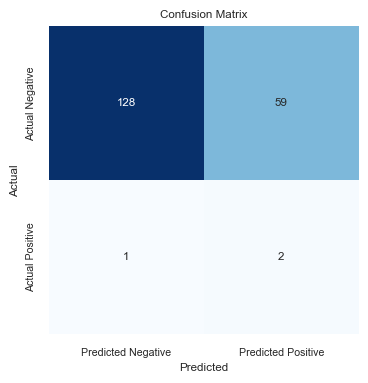

/var/folders/6z/8jmv33nx765dnhhppmf26ljc0000gp/T/ipykernel_5497/751384904.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best')


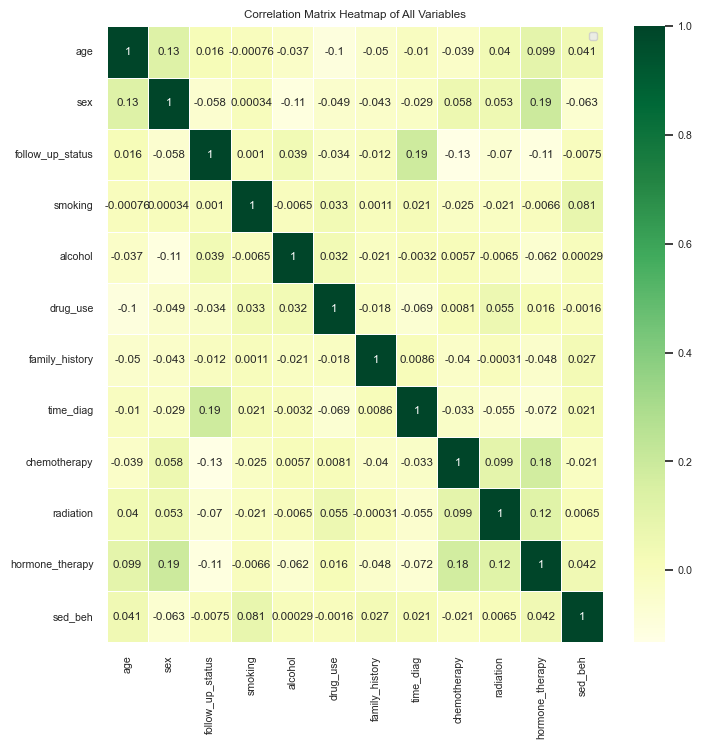

Classification Report:
              precision    recall  f1-score   support

         0.0       0.99      0.68      0.81       187
         1.0       0.03      0.67      0.06         3

    accuracy                           0.68       190
   macro avg       0.51      0.68      0.44       190
weighted avg       0.98      0.68      0.80       190



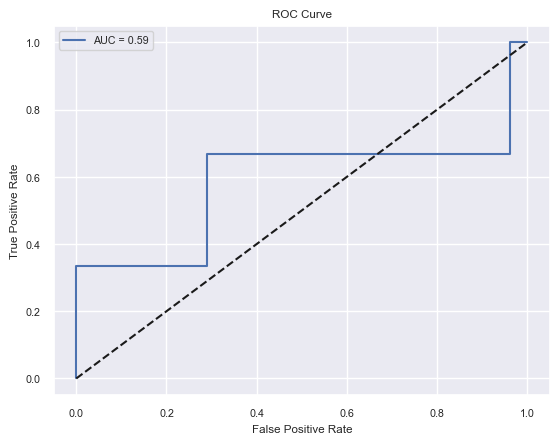

AUC: 0.5882352941176471
Class distribution in y_pred: {np.float64(0.0): np.int64(187), np.float64(1.0): np.int64(3)}
         Current function value: 0.079036
         Iterations: 35
             Feature  Coefficient  Odds Ratio  CI Lower  CI Upper
5           drug_use     0.631772    1.880940  1.129351  3.132715
8       chemotherapy     0.352626    1.422799  0.788599  2.567027
0                age     0.321659    1.379414  0.724574  2.626071
11           sed_beh     0.192314    1.212052  0.692825  2.120404
6     family_history     0.160591    1.174205  0.711299  1.938367
1                sex     0.119076    1.126456  0.633702  2.002366
10   hormone_therapy     0.113406    1.120086  0.662969  1.892385
7          time_diag     0.030871    1.031352  0.574887  1.850253
4            alcohol     0.013239    1.013327  0.573877  1.789290
2   follow_up_status    -0.116718    0.889836  0.482836  1.639910
9          radiation    -0.633385    0.530792  0.270618  1.041098
3            smoking    -

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [18]:
#Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_elas_pred)
plt.figure(figsize=(4, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Correlation matrix
correlation_matrix = X.corr()
plt.figure(figsize=(8, 8))
sns.set(font_scale=0.7)
sns.heatmap(correlation_matrix, annot=True, cmap="YlGn", linewidths=.5)
plt.title("Correlation Matrix Heatmap of All Variables")
plt.legend(loc='best')
plt.show()

print('Classification Report:')
print(classification_report(y_test, y_elas_pred))

# The coefficients
coef = log_reg.coef_

# Convert coefficients to odds ratios
odds_ratios = np.exp(coef)

# ROC Curve and AUC
fpr, tpr, _ = roc_curve(y_test, y_elas_prob)
auc = roc_auc_score(y_test, y_prob, average='micro') # micro: Calculate metrics globally by counting the total true positives, false negatives and false positives.    

plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='best')
plt.show()
print('AUC:', auc)

unique_test, counts_test = np.unique(y_test, return_counts=True)
print(f'Class distribution in y_pred: {dict(zip(unique_test, counts_test))}')

# Calculate standard errors
# The standard errors can be approximated from the inverse of the Hessian matrix (covariance matrix)
import statsmodels.api as sm
log_reg_sm = sm.Logit(y_train, sm.add_constant(X_train)).fit()
standard_errors = log_reg_sm.bse[1:]  # Exclude the intercept

# Calculate confidence intervals
z = 1.96  # Z-score for 95% confidence interval
conf_intervals = np.array([coef.flatten() - z * standard_errors, coef.flatten() + z * standard_errors]).T
conf_intervals_odds = np.exp(conf_intervals)

# Flatten the arrays to ensure they are 1-dimensional
coef_odds = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coef.flatten(),
    'Odds Ratio': odds_ratios.flatten(),
    'CI Lower': conf_intervals_odds[:, 0],
    'CI Upper': conf_intervals_odds[:, 1]
})

coef_odds_sorted = coef_odds.sort_values(by='Coefficient', ascending=False)
print(coef_odds_sorted)



# Eval: Random Search w CV

In [19]:
from scipy.stats import uniform
from sklearn.model_selection import RandomizedSearchCV
# Define the parameter distributions
param_dist = {
    'C': uniform(loc=0.01, scale=100),  # Uniform distribution between 0.01 and 100
    'l1_ratio': uniform(loc=0, scale=1)  # Uniform distribution between 0 and 1
}

# Perform Random Search with cross-validation
random_search = RandomizedSearchCV(log_reg, param_distributions=param_dist, n_iter=100, cv=5, scoring='roc_auc', verbose=1, n_jobs=-1, random_state=42)
random_search.fit(X_train, y_train)

# Get the best parameters
best_params = random_search.best_params_
print("Best parameters found: ", best_params)

# Train the logistic regression model with the best parameters
best_log_reg = random_search.best_estimator_
best_log_reg.fit(X_train, y_train)

# Predict on the test set
y_pred_CV = best_log_reg.predict(X_test)
y_prob_CV = best_log_reg.predict_proba(X_test)[:, 1]

Fitting 5 folds for each of 100 candidates, totalling 500 fits


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/skle

Best parameters found:  {'C': np.float64(0.5622117123602399), 'l1_ratio': np.float64(0.8154614284548342)}


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/skle

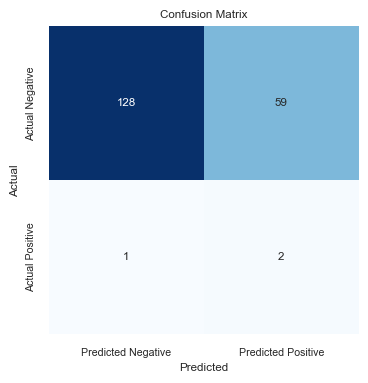

/var/folders/6z/8jmv33nx765dnhhppmf26ljc0000gp/T/ipykernel_5497/3217920072.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best')


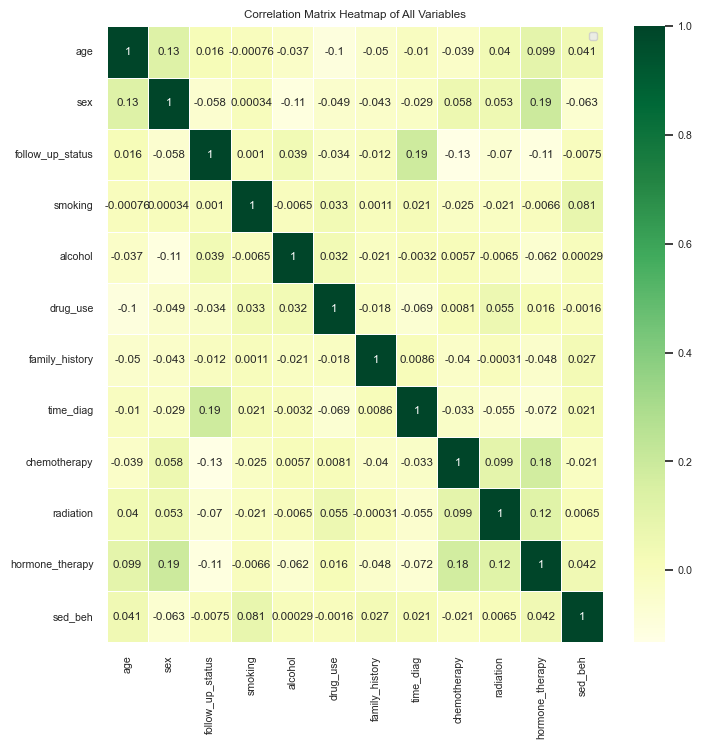

Classification Report:
              precision    recall  f1-score   support

         0.0       0.99      0.68      0.81       187
         1.0       0.03      0.67      0.06         3

    accuracy                           0.68       190
   macro avg       0.51      0.68      0.44       190
weighted avg       0.98      0.68      0.80       190



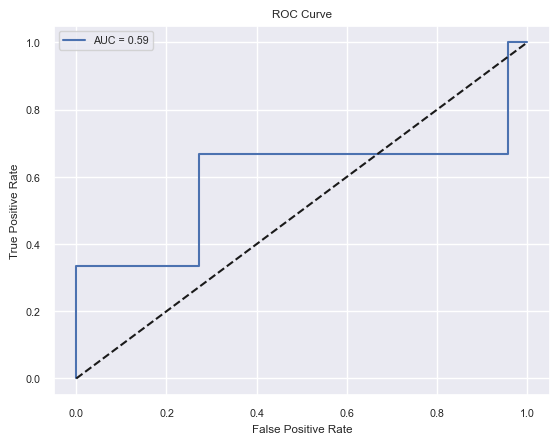

AUC: 0.5882352941176471
Class distribution in y_pred: {np.float64(0.0): np.int64(187), np.float64(1.0): np.int64(3)}
         Current function value: 0.079036
         Iterations: 35
             Feature  Coefficient  Odds Ratio  CI Lower  CI Upper
5           drug_use     0.631772    1.880940  1.129351  3.132715
8       chemotherapy     0.352626    1.422799  0.788599  2.567027
0                age     0.321659    1.379414  0.724574  2.626071
11           sed_beh     0.192314    1.212052  0.692825  2.120404
6     family_history     0.160591    1.174205  0.711299  1.938367
1                sex     0.119076    1.126456  0.633702  2.002366
10   hormone_therapy     0.113406    1.120086  0.662969  1.892385
7          time_diag     0.030871    1.031352  0.574887  1.850253
4            alcohol     0.013239    1.013327  0.573877  1.789290
2   follow_up_status    -0.116718    0.889836  0.482836  1.639910
9          radiation    -0.633385    0.530792  0.270618  1.041098
3            smoking    -

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [20]:
#Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred_CV)
plt.figure(figsize=(4, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Correlation matrix
correlation_matrix = X.corr()
plt.figure(figsize=(8, 8))
sns.set(font_scale=0.7)
sns.heatmap(correlation_matrix, annot=True, cmap="YlGn", linewidths=.5)
plt.title("Correlation Matrix Heatmap of All Variables")
plt.legend(loc='best')
plt.show()

print('Classification Report:')
print(classification_report(y_test, y_pred_CV))

# The coefficients
coef = log_reg.coef_

# Convert coefficients to odds ratios
odds_ratios = np.exp(coef)

# ROC Curve and AUC
fpr, tpr, _ = roc_curve(y_test, y_prob_CV)
auc = roc_auc_score(y_test, y_prob, average='micro') # micro: Calculate metrics globally by counting the total true positives, false negatives and false positives.    

plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='best')
plt.show()
print('AUC:', auc)

unique_test, counts_test = np.unique(y_test, return_counts=True)
print(f'Class distribution in y_pred: {dict(zip(unique_test, counts_test))}')

# Calculate standard errors
# The standard errors can be approximated from the inverse of the Hessian matrix (covariance matrix)
import statsmodels.api as sm
log_reg_sm = sm.Logit(y_train, sm.add_constant(X_train)).fit()
standard_errors = log_reg_sm.bse[1:]  # Exclude the intercept

# Calculate confidence intervals
z = 1.96  # Z-score for 95% confidence interval
conf_intervals = np.array([coef.flatten() - z * standard_errors, coef.flatten() + z * standard_errors]).T
conf_intervals_odds = np.exp(conf_intervals)

# Flatten the arrays to ensure they are 1-dimensional
coef_odds = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coef.flatten(),
    'Odds Ratio': odds_ratios.flatten(),
    'CI Lower': conf_intervals_odds[:, 0],
    'CI Upper': conf_intervals_odds[:, 1]
})

coef_odds_sorted = coef_odds.sort_values(by='Coefficient', ascending=False)
print(coef_odds_sorted)



## Decision tree - feature importances

Training Accuracy Tree: 0.97
Classification Report Tree:
              precision    recall  f1-score   support

         0.0       0.98      0.98      0.98       187
         1.0       0.00      0.00      0.00         3

    accuracy                           0.97       190
   macro avg       0.49      0.49      0.49       190
weighted avg       0.97      0.97      0.97       190

             Feature  Importance
7          time_diag    0.473721
0                age    0.169799
9          radiation    0.073058
11           sed_beh    0.060569
8       chemotherapy    0.053113
1                sex    0.041585
5           drug_use    0.038078
2   follow_up_status    0.035244
4            alcohol    0.028122
6     family_history    0.026710
3            smoking    0.000000
10   hormone_therapy    0.000000


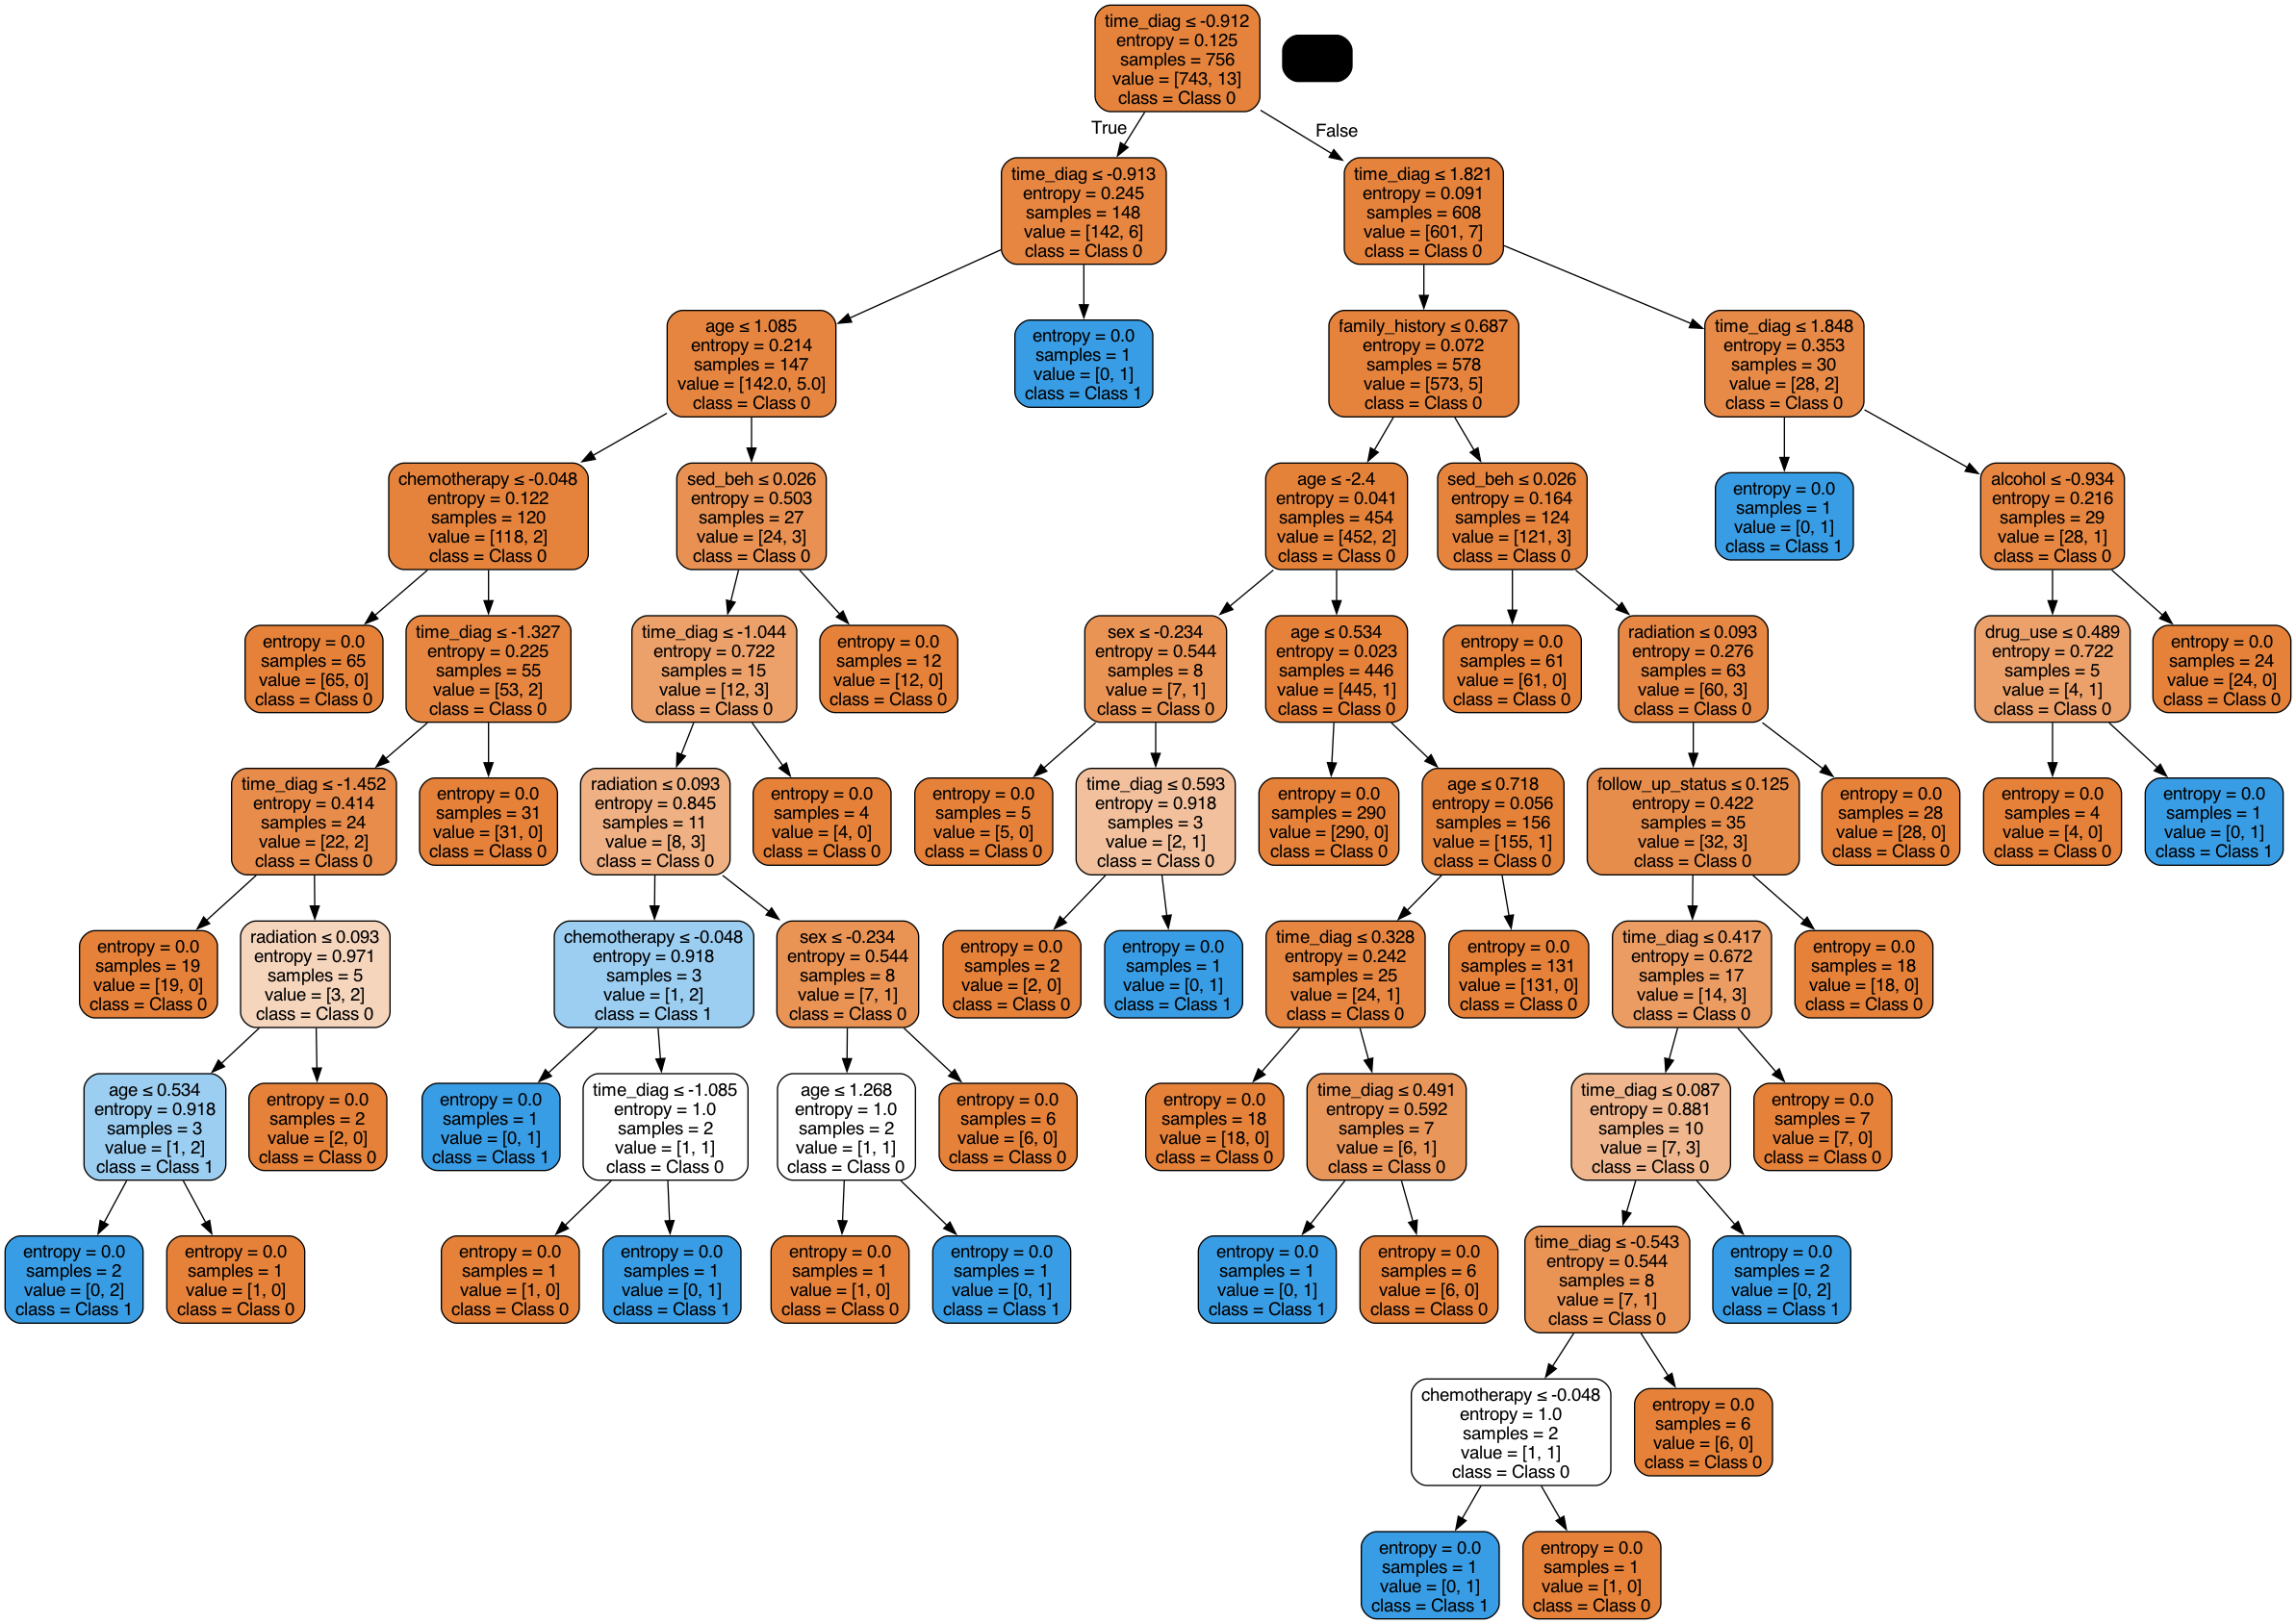

In [21]:
# Train a decision tree to calculate feature importances (entropy)
tree_model = DecisionTreeClassifier(criterion='entropy', random_state=42) #gini better
tree_model.fit(X_train, y_train)

# Make predictions using the testing set
y_tree_pred = tree_model.predict(X_test)  # Predicted labels for X_test
y_tree_pred_prob = tree_model.predict_proba(X_test)[:, 1]  # Predicted probabilities of the positive class (class 1)

# Calculate training accuracy
train_accuracy_tree = accuracy_score(y_test, y_tree_pred)
print(f'Training Accuracy Tree: {train_accuracy_tree:.2f}')

print('Classification Report Tree:')
print(classification_report(y_test, y_tree_pred))

feature_importances_tree = tree_model.feature_importances_

# Create a DataFrame to map feature importances to column names
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importances_tree
})

# Sort the DataFrame by importance
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print(feature_importance_df)

# Export the decision tree to a DOT file
dot_data = export_graphviz(tree_model, out_file=None, 
                        feature_names=X.columns,
                        class_names=['Class 0', 'Class 1'],
                        filled=True, rounded=True, special_characters=True)

# Use graphviz to create a graph from the DOT data
graph = pydotplus.graph_from_dot_data(dot_data)

# Display the graph
display(Image(graph.create_png()))